In [1]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter(action="ignore", category=FutureWarning)
    import os, math
    from pathlib import Path
    import scanpy as sc
    import numpy as np
    import seaborn as sns
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from tqdm import tqdm
    from scipy import stats
    from scipy.stats import pearsonr, spearmanr
    from scipy.sparse import issparse

pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", None)

os.chdir(".././")
!pwd

../.


In [2]:
%load_ext autoreload
%autoreload 1

%aimport s7_helpers
import s7_helpers

In [3]:
# plt.rcParams["figure.dpi"] = 80

### Analyze corr metrics

In [4]:
corr_df = pd.read_csv(
    ".././5.3_2_dw_level_corr_stats.csv",
    index_col=0,
)
corr_df.head(3)

,Tissue_global,cell_type,pearson_r,pearson_p,spearman_r,spearman_p,n_donors,pearson_fdr,spearman_fdr,method,level
0,Colon,Crypt stem cells,0.015222,0.950681,0.016696,0.945913,19,0.950681,0.962805,sp,ct
1,Colon,Enterocytes,-0.139074,0.516913,-0.245049,0.248456,24,0.758776,0.643728,sp,ct
2,Colon,Fibroblasts,0.453291,0.044725,0.456498,0.043050,20,0.224405,0.243191,sp,ct


In [5]:
"""all metrics"""


def calculate_summary(group, corr):
    """Summary function"""
    rho = group[f"{corr}_r"].dropna()
    n = len(rho)
    q1 = rho.quantile(0.25)
    median = rho.median()
    q3 = rho.quantile(0.75)

    return pd.Series(
        {
            # Number of tests
            f"n_tests": n,
            # Central tendency / effect size
            f"median_{corr}_r": median,
            # f"mean_{corr}_r": rho.mean(),
            # Directional consistency
            f"n_pos_{corr}": (rho > 0).sum(),
            f"percent_pos_{corr}": (rho > 0).mean() * 100,
            # Significant positive associations
            f"n_pos_FDR05_{corr}": (
                (group[f"{corr}_r"] > 0) & (group[f"{corr}_fdr"] < FDR_THRESHOLD)
            ).sum(),
            f"percent_pos_FDR05_{corr}": (
                (group[f"{corr}_r"] > 0) & (group[f"{corr}_fdr"] < FDR_THRESHOLD)
            ).mean()
            * 100,
            # Heterogeneity
            f"q1_{corr}": q1,
            f"q3_{corr}": q3,
            f"IQR_{corr}": q3 - q1,
            f"std_{corr}": rho.std(),
            # Additional information
            # f"min_r_{corr}": rho.min(), f"max_r_{corr}": rho.max(),
        }
    )


FDR_THRESHOLD = 0.05

metrics_dfs = []
for corr in "pearson", "spearman":
    df = corr_df.copy()
    df = df.dropna(subset=[f"{corr}_r"])

    # Булевы признаки
    df[f"positive_{corr}"] = df[f"{corr}_r"] > 0
    df[f"positive_signif_{corr}"] = (df[f"{corr}_r"] > 0) & (
        df[f"{corr}_fdr"] < FDR_THRESHOLD
    )

    # ============================================================
    # Calculate Method × Level statistics
    # ============================================================

    metrics_df = (
        df.groupby(["method", "level"], observed=True)
        .apply(lambda group: calculate_summary(group, corr), include_groups=False)
        .reset_index()
    )

    metrics_dfs.append(metrics_df)

In [6]:
order = [
    "method",
    "level",
    "n_tests",
    "median_pearson_r",
    "median_spearman_r",
    "n_pos_pearson",
    "n_pos_spearman",
    "percent_pos_pearson",
    "percent_pos_spearman",
    "n_pos_FDR05_pearson",
    "n_pos_FDR05_spearman",
    "percent_pos_FDR05_pearson",
    "percent_pos_FDR05_spearman",
    "q1_pearson",
    "q1_spearman",
    "q3_pearson",
    "q3_spearman",
    "IQR_pearson",
    "IQR_spearman",
    "std_pearson",
    "std_spearman",
]

metrics_df = pd.concat(metrics_dfs, axis=1)
metrics_df = metrics_df[order]
metrics_df = metrics_df.loc[:, ~metrics_df.columns.duplicated()]
metrics_df

,method,level,n_tests,median_pearson_r,median_spearman_r,n_pos_pearson,n_pos_spearman,percent_pos_pearson,percent_pos_spearman,n_pos_FDR05_pearson,n_pos_FDR05_spearman,percent_pos_FDR05_pearson,percent_pos_FDR05_spearman,q1_pearson,q1_spearman,q3_pearson,q3_spearman,IQR_pearson,IQR_spearman,std_pearson,std_spearman
0,ds,ct,72.0,0.016853,0.010560,38.0,38.0,52.777778,52.777778,0.0,0.0,0.0,0.000000,-0.179303,-0.240409,0.344180,0.290847,0.523483,0.531256,0.427084,0.412933
1,ds,gse,72.0,0.005089,0.008503,38.0,37.0,52.777778,51.388889,0.0,0.0,0.0,0.000000,-0.181768,-0.177705,0.302388,0.369030,0.484156,0.546735,0.423612,0.406391
2,ds,gsm,72.0,0.026987,0.007042,39.0,36.0,54.166667,50.000000,0.0,0.0,0.0,0.000000,-0.146828,-0.208470,0.244895,0.261219,0.391723,0.469689,0.382783,0.391423
3,sid,ct,72.0,-0.026845,-0.023601,32.0,33.0,44.444444,45.833333,0.0,1.0,0.0,1.388889,-0.219372,-0.260560,0.173978,0.165482,0.393350,0.426042,0.374922,0.389880
4,sid,gse,72.0,-0.032996,0.004587,34.0,36.0,47.222222,50.000000,0.0,0.0,0.0,0.000000,-0.311969,-0.232995,0.204081,0.203770,0.516050,0.436765,0.408005,0.411305
5,sid,gsm,72.0,-0.005582,0.005136,36.0,36.0,50.000000,50.000000,0.0,1.0,0.0,1.388889,-0.278668,-0.269378,0.219668,0.233155,0.498336,0.502533,0.403872,0.401943
6,sp,ct,57.0,0.339195,0.250570,50.0,45.0,87.719298,78.947368,0.0,2.0,0.0,3.508772,0.082406,0.055923,0.538298,0.455946,0.455892,0.400022,0.298974,0.303921
7,sp,gse,57.0,0.223986,0.201740,42.0,41.0,73.684211,71.929825,0.0,2.0,0.0,3.508772,-0.024531,-0.055948,0.397826,0.384941,0.422357,0.440889,0.333999,0.317216
8,sp,gsm,57.0,-0.012857,0.059361,28.0,31.0,49.122807,54.385965,0.0,1.0,0.0,1.754386,-0.238064,-0.166667,0.323359,0.224956,0.561423,0.391623,0.358775,0.336252


In [ ]:
"""ранжирование на основе метрик по корр Пирсона"""
rank_cols = [
    "median_pearson_r",
    "n_pos_pearson",
    "percent_pos_pearson",
    "n_pos_FDR05_pearson",
    "percent_pos_FDR05_pearson",
]

id_cols = ["method", "level", "n_tests"]

# создаём новый DataFrame с идентифицирующими столбцами
rank_df = metrics_df[id_cols].copy()

# добавляем ранги для каждой метрики
rank_df[[f"{col}_rank" for col in rank_cols]] = metrics_df[rank_cols].rank(
    ascending=False, method="min"
)

# средний ранг
rank_df["mean_rank"] = rank_df[[f"{col}_rank" for col in rank_cols]].mean(axis=1)

rank_df = rank_df.sort_values("mean_rank").reset_index(drop=True)
rank_df

,method,level,n_tests,median_pearson_r_rank,n_pos_pearson_rank,percent_pos_pearson_rank,n_pos_FDR05_pearson_rank,percent_pos_FDR05_pearson_rank,mean_rank
0,sp,ct,57.0,1.0,1.0,1.0,1.0,1.0,1.0
1,sp,gse,57.0,2.0,2.0,2.0,1.0,1.0,1.6
2,ds,gsm,72.0,3.0,3.0,3.0,1.0,1.0,2.2
3,ds,ct,72.0,4.0,4.0,4.0,1.0,1.0,2.8
4,ds,gse,72.0,5.0,4.0,4.0,1.0,1.0,3.0
5,sid,gsm,72.0,6.0,6.0,6.0,1.0,1.0,4.0
6,sp,gsm,57.0,7.0,9.0,7.0,1.0,1.0,5.0
7,sid,gse,72.0,9.0,7.0,8.0,1.0,1.0,5.2
8,sid,ct,72.0,8.0,8.0,9.0,1.0,1.0,5.4


In [ ]:
"""ранжирование на основе метрик по корр Спирмена"""

rank_cols = [
    "median_spearman_r",
    "n_pos_spearman",
    "percent_pos_spearman",
    "n_pos_FDR05_spearman",
    "percent_pos_FDR05_spearman",
    "median_pearson_r",
    "n_pos_pearson",
    "percent_pos_pearson",
    "n_pos_FDR05_pearson",
    "percent_pos_FDR05_pearson",
]

id_cols = ["method", "level", "n_tests"]

# создаём новый DataFrame с идентифицирующими столбцами
rank_df = metrics_df[id_cols].copy()

# добавляем ранги для каждой метрики
rank_df[[f"{col}_rank" for col in rank_cols]] = metrics_df[rank_cols].rank(
    ascending=False, method="min"
)

# средний ранг
rank_df["mean_rank"] = rank_df[[f"{col}_rank" for col in rank_cols]].mean(axis=1)

rank_df = rank_df.sort_values("mean_rank").reset_index(drop=True)
rank_df

,method,level,n_tests,median_spearman_r_rank,n_pos_spearman_rank,percent_pos_spearman_rank,n_pos_FDR05_spearman_rank,percent_pos_FDR05_spearman_rank,median_pearson_r_rank,n_pos_pearson_rank,percent_pos_pearson_rank,n_pos_FDR05_pearson_rank,percent_pos_FDR05_pearson_rank,mean_rank
0,sp,ct,57.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,sp,gse,57.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,1.6
2,ds,ct,72.0,4.0,3.0,4.0,6.0,6.0,4.0,4.0,4.0,1.0,1.0,3.7
3,ds,gsm,72.0,6.0,5.0,6.0,6.0,6.0,3.0,3.0,3.0,1.0,1.0,4.0
4,ds,gse,72.0,5.0,4.0,5.0,6.0,6.0,5.0,4.0,4.0,1.0,1.0,4.1
5,sid,gsm,72.0,7.0,5.0,6.0,3.0,4.0,6.0,6.0,6.0,1.0,1.0,4.5
6,sp,gsm,57.0,3.0,9.0,3.0,3.0,3.0,7.0,9.0,7.0,1.0,1.0,4.6
7,sid,gse,72.0,8.0,5.0,6.0,6.0,6.0,9.0,7.0,8.0,1.0,1.0,5.7
8,sid,ct,72.0,9.0,8.0,9.0,3.0,4.0,8.0,8.0,9.0,1.0,1.0,6.0


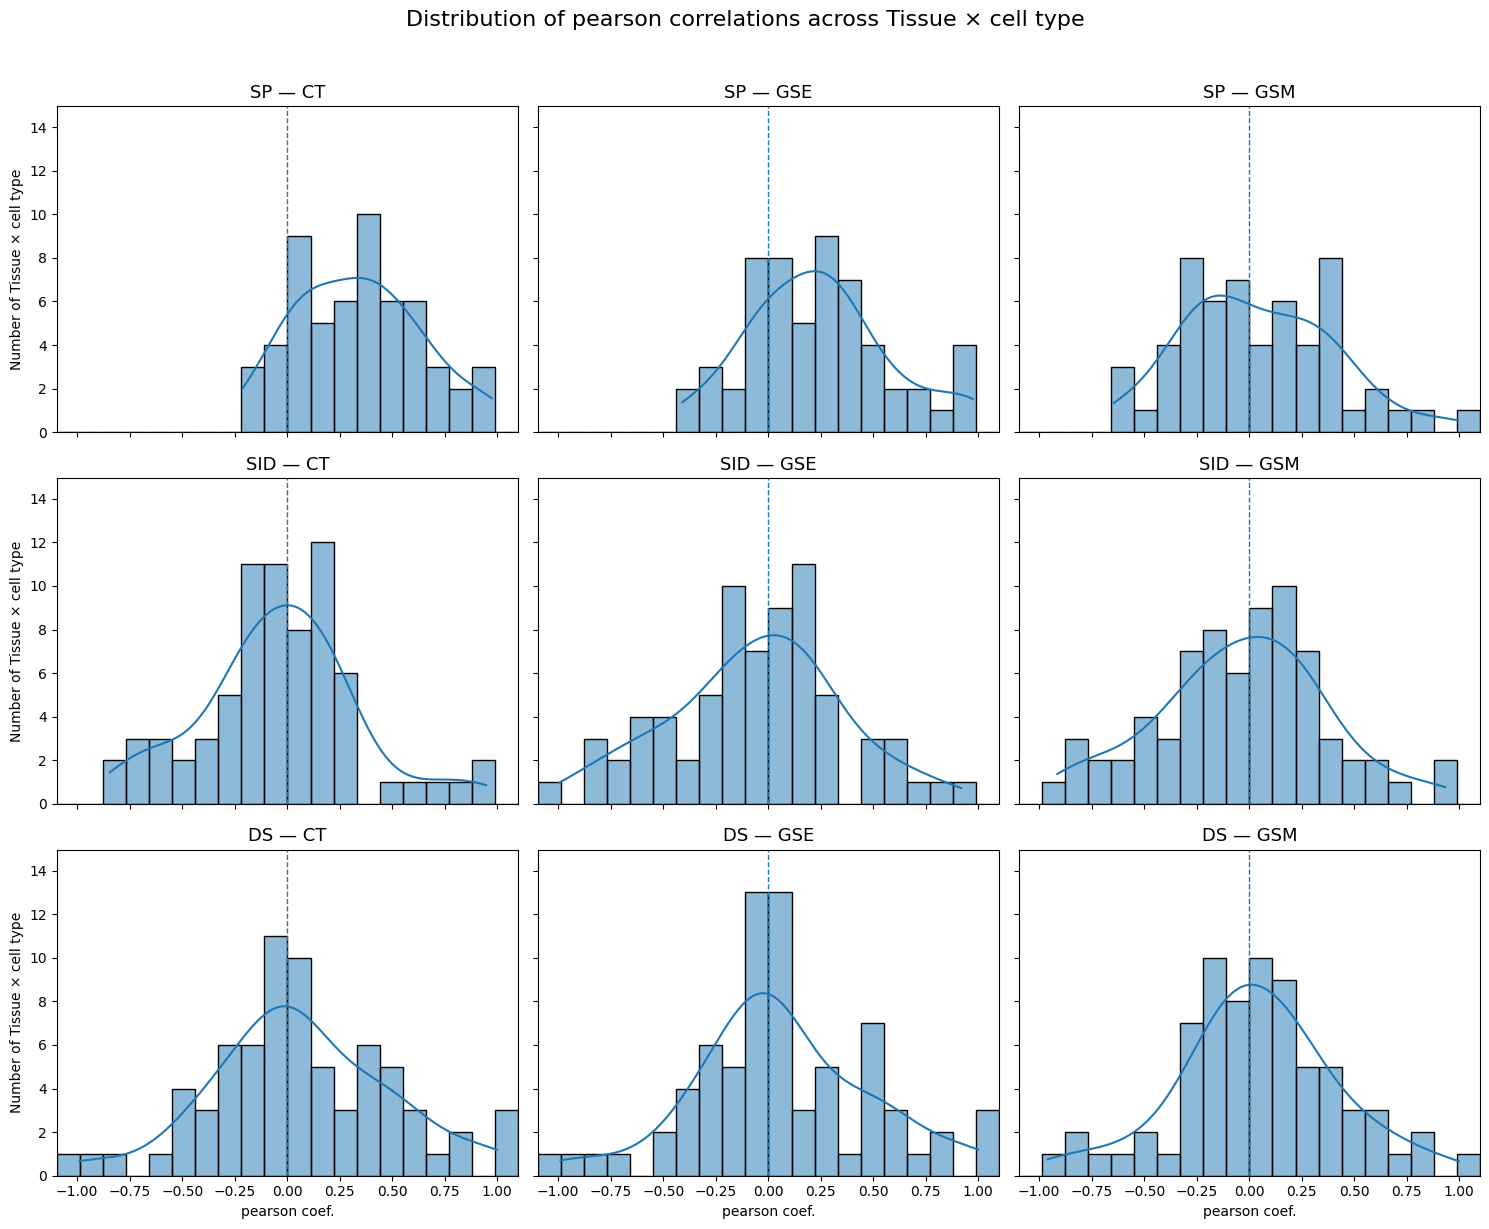

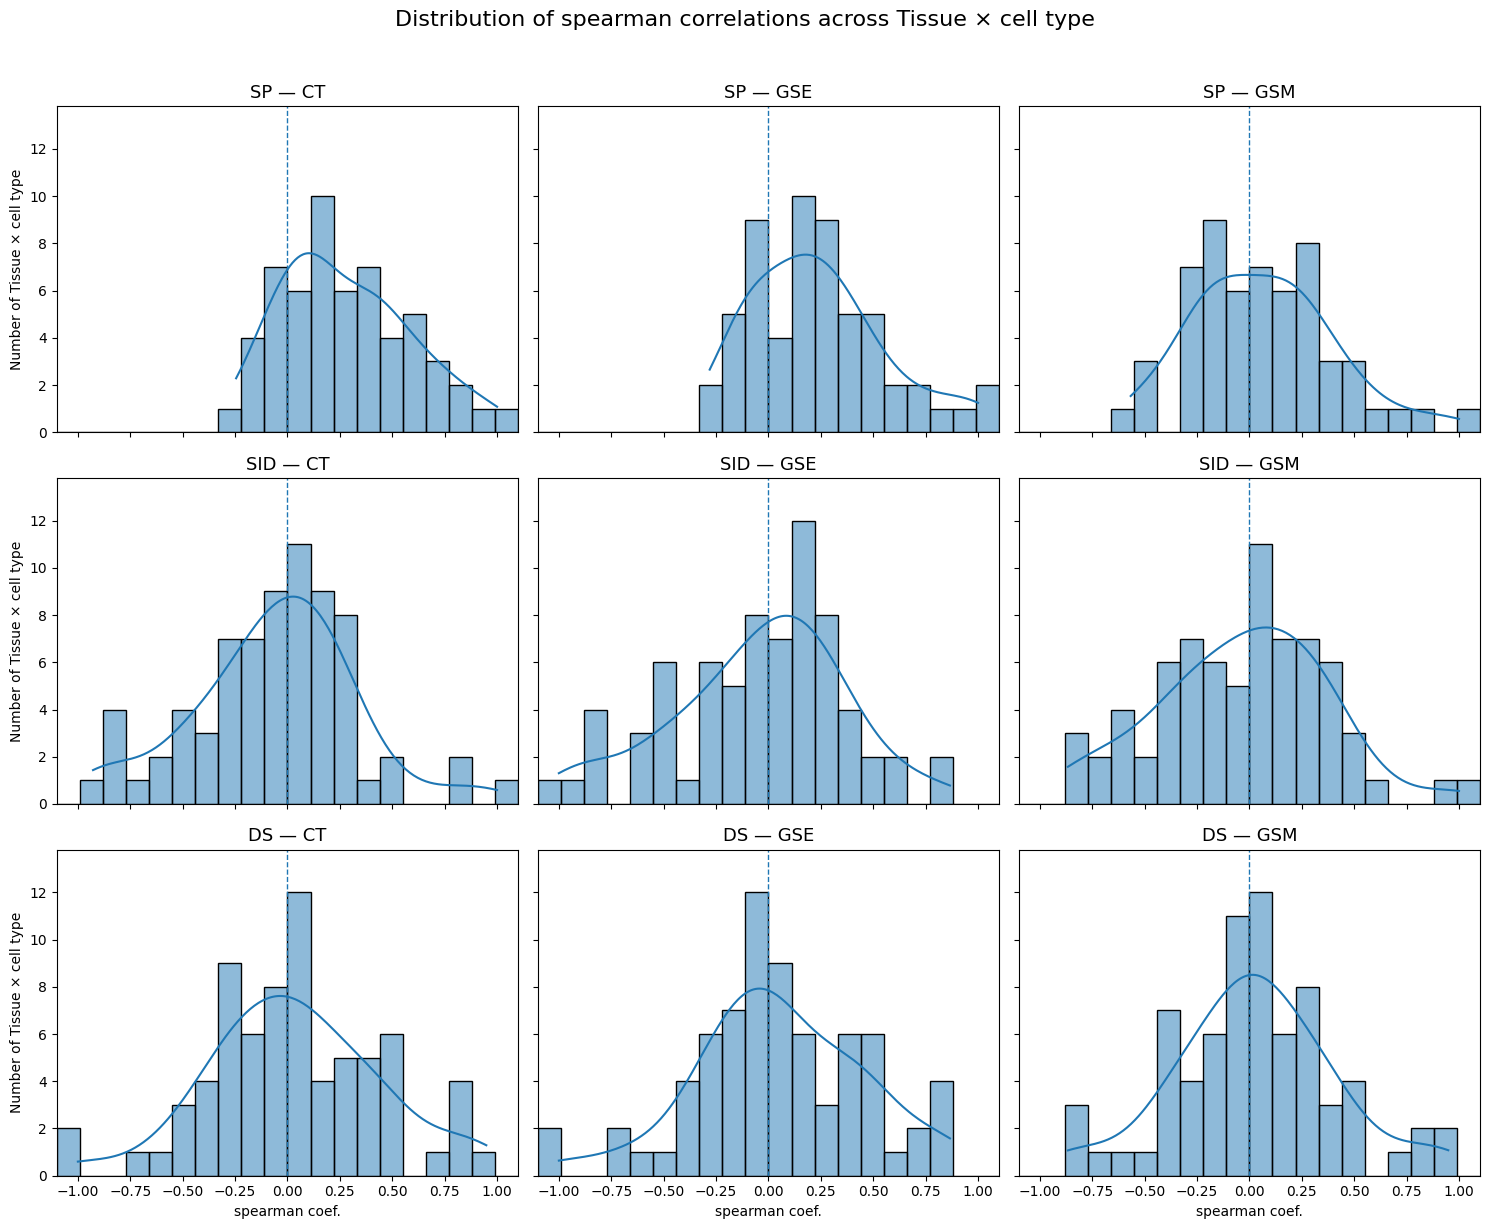

In [9]:
"""spearman rho distributions"""

method_order = ["sp", "sid", "ds"]
level_order = ["ct", "gse", "gsm"]

method_labels = {"sp": "SP", "sid": "SID", "ds": "DS"}
level_labels = {"ct": "CT", "gse": "GSE", "gsm": "GSM"}

for corr in "pearson", "spearman":
    plot_df = corr_df.dropna(subset=[f"{corr}_r"]).copy()
    # X: общий диапазон
    x_min = plot_df[f"{corr}_r"].min()
    x_max = plot_df[f"{corr}_r"].max()
    # Немного расширяем диапазон
    x_margin = 0.05 * (x_max - x_min)
    x_lim = (x_min - x_margin, x_max + x_margin)

    # Y: сначала определяем максимальную высоту histogram
    # при одинаковом количестве bins
    n_bins = 20
    max_count = 0

    for method in method_order:
        for level in level_order:
            values = plot_df.loc[
                (plot_df["method"] == method) & (plot_df["level"] == level), f"{corr}_r"
            ]
            counts, _ = np.histogram(values, bins=n_bins, range=x_lim)
            if len(counts) > 0:
                max_count = max(max_count, counts.max())

    y_lim = (0, max_count * 1.15)

    # Figure 3 × 3
    fig, axes = plt.subplots(
        nrows=3, ncols=3, figsize=(15, 12), sharex=True, sharey=True
    )

    for i, method in enumerate(method_order):
        for j, level in enumerate(level_order):
            ax = axes[i, j]
            values = plot_df.loc[
                (plot_df["method"] == method) & (plot_df["level"] == level), f"{corr}_r"
            ]

            # Histogram
            sns.histplot(
                values, bins=n_bins, binrange=x_lim, stat="count", kde=True, ax=ax
            )
            ax.axvline(0, linestyle="--", linewidth=1)  # Zero correlation line

            # Общие пределы
            ax.set_xlim(x_lim)
            ax.set_ylim(y_lim)

            ax.set_title(
                f"{method_labels[method]} — {level_labels[level]}", fontsize=13
            )

            # Подписи только по краям
            if i == 2:
                ax.set_xlabel(f"{corr} coef.")
            else:
                ax.set_xlabel("")

            if j == 0:
                ax.set_ylabel("Number of Tissue × cell type")
            else:
                ax.set_ylabel("")

    fig.suptitle(
        f"Distribution of {corr} correlations across Tissue × cell type",
        fontsize=16,
        y=1.02,
    )

    plt.tight_layout()

    # plt.savefig(
    #     "spearman_rho_distributions_3x3.png",
    #     dpi=300,
    #     bbox_inches="tight"
    # )

    plt.show()

### **primary binarization level** - уровень бинаризации Sc/NSc клеток при помощи GMM

см. график выше

критерий - наибольшее число положительных корреляций % сен клеток с возрастом. *Вне зависимости от уровня значимости* (тк предполагаем, что оч шумные данные, смотрим на направление)

### viz - spearman

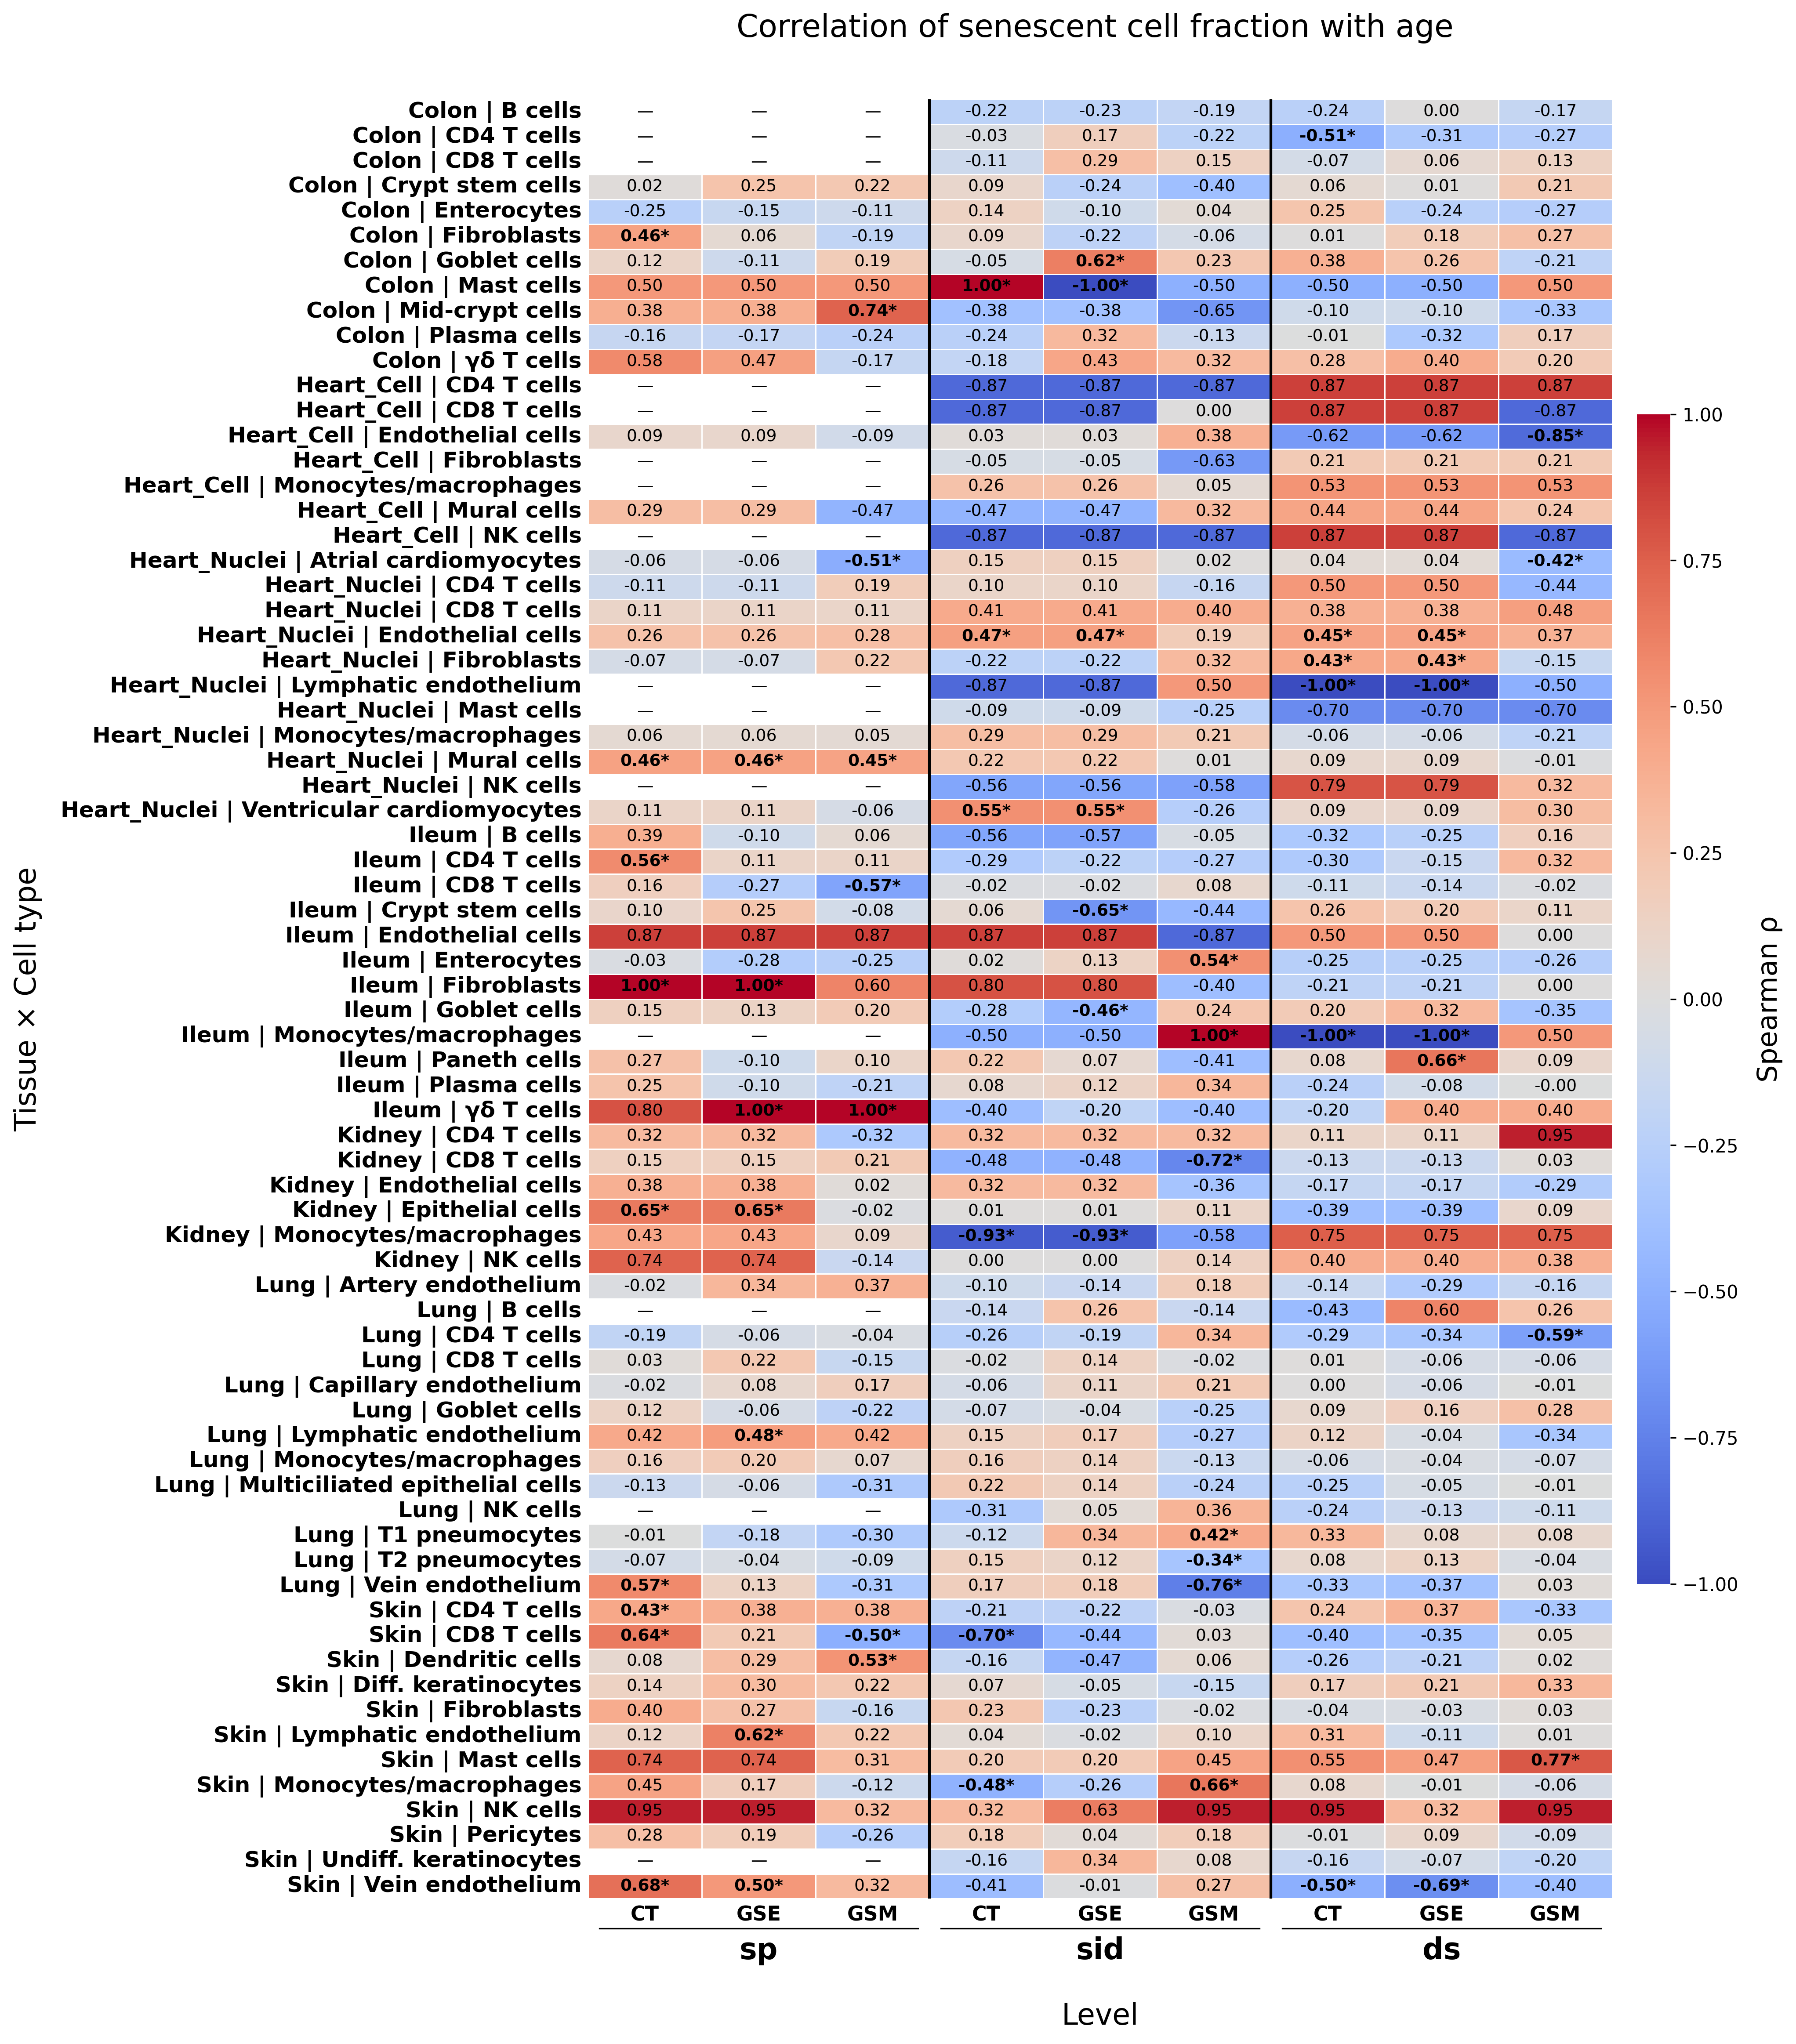

In [ ]:
plot_df = corr_df.copy()

# Данные

# Строка для heatmap
plot_df["Tissue_cell_type"] = plot_df["Tissue_global"] + " | " + plot_df["cell_type"]
# Названия колонок
plot_df["Method_Level"] = plot_df["method"] + " | " + plot_df["level"].str.upper()

# Pivot для rho
heatmap_rho = plot_df.pivot(
    index="Tissue_cell_type", columns="Method_Level", values="spearman_r"
)

# Pivot для FDR
heatmap_fdr = plot_df.pivot(
    index="Tissue_cell_type", columns="Method_Level", values="spearman_p"
)

# Порядок колонок
method_order = ["sp", "sid", "ds"]
level_order = ["CT", "GSE", "GSM"]

column_order = [
    f"{method} | {level}" for method in method_order for level in level_order
]

# Оставляем только существующие
column_order = [col for col in column_order if col in heatmap_rho.columns]

heatmap_rho = heatmap_rho[column_order]
heatmap_fdr = heatmap_fdr[column_order]


# Размеры heatmap
n_rows, n_cols = heatmap_rho.shape

# Plot
fig, ax = plt.subplots(figsize=(13, max(8, len(heatmap_rho) * 0.24)), dpi=300)

sns.heatmap(
    heatmap_rho,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    # Значения теперь рисуем вручную
    annot=False,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Spearman ρ",
        "shrink": 0.65,
        "aspect": 35,
        "pad": 0.02,
    },
    ax=ax,
)


# Значения внутри heatmap
for row in range(n_rows):
    for col in range(n_cols):
        rho = heatmap_rho.iloc[row, col]
        fdr = heatmap_fdr.iloc[row, col]

        # Отсутствующее значение
        if pd.isna(rho):
            ax.text(
                col + 0.5,
                row + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=9,
                color="black",
            )

        # Значение
        else:
            # Статистическая значимость
            significant = not pd.isna(fdr) and fdr < 0.05

            if significant:
                text = f"{rho:.2f}*"
                fontweight = "bold"
            else:
                text = f"{rho:.2f}"
                fontweight = "normal"

            ax.text(
                col + 0.5,
                row + 0.5,
                text,
                ha="center",
                va="center",
                fontsize=9,
                fontweight=fontweight,
                color="black",
            )

# Разделительные линии между методами
for x in [3, 6]:
    if x < n_cols:
        ax.axvline(x, color="black", linewidth=1.5, zorder=10)

# Подписи осей
ax.set_xlabel(
    "Level",
    fontsize=16,
    labelpad=42,
)
ax.set_ylabel(
    "Tissue × Cell type",
    fontsize=16,
    labelpad=10,
)
ax.set_title(
    "Correlation of senescent cell fraction with age \n",
    fontsize=17,
    pad=15,
)

# X-axis: только уровень
level_labels = [col.split(" | ")[1] for col in heatmap_rho.columns]
ax.set_xticklabels(
    level_labels,
    fontsize=11,
    fontweight="semibold",
    rotation=0,
)
ax.tick_params(
    axis="x",
    length=0,
)

# Y-axis
ax.tick_params(
    axis="y",
    labelsize=12,
    length=0,
)

for label in ax.get_yticklabels():
    label.set_fontweight("semibold")

# Названия методов под группами
method_centers = []
method_labels = []

for method in method_order:
    method_columns = [
        col for col in heatmap_rho.columns if col.startswith(f"{method} |")
    ]
    if len(method_columns) == 0:
        continue

    first_col = heatmap_rho.columns.get_loc(method_columns[0])
    last_col = heatmap_rho.columns.get_loc(method_columns[-1])
    center = (first_col + last_col + 1) / 2

    method_centers.append(center)
    method_labels.append(method)

# Горизонтальные линии под группами уровней
line_y = n_rows + 1.18
for method in method_order:
    method_columns = [
        col for col in heatmap_rho.columns if col.startswith(f"{method} |")
    ]

    if len(method_columns) == 0:
        continue

    first_col = heatmap_rho.columns.get_loc(method_columns[0])
    last_col = heatmap_rho.columns.get_loc(method_columns[-1])

    ax.plot(
        [first_col + 0.1, last_col + 0.9],
        [line_y, line_y],
        color="black",
        linewidth=0.8,
        clip_on=False,
    )

# Подписи методов
for center, method in zip(method_centers, method_labels):
    ax.text(
        center,
        n_rows + 2.08,
        method,
        ha="center",
        va="center",
        fontsize=16,
        fontweight="semibold",
        clip_on=False,
    )

# Colorbar
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(
    labelsize=10,
    length=3,
)
cbar.set_label(
    "Spearman ρ",
    fontsize=15,
    labelpad=10,
)

# Размеры полей
plt.subplots_adjust(
    bottom=0.15,
    top=0.94,
    left=0.20,
    right=0.92,
)
# plt.savefig("heatmap_spearman_rho.png",dpi=300,bbox_inches="tight")

plt.show()

/tmp/ipykernel_12191/4006434988.py:27: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(
/tmp/ipykernel_12191/4006434988.py:53: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Cell type (CT)", "Study / GSE", "Sample / GSM"])


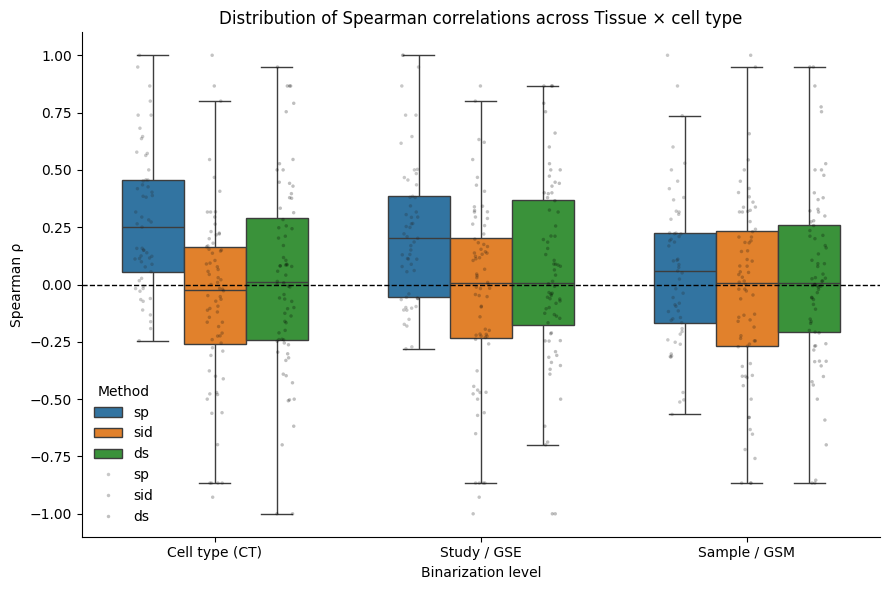

In [11]:
"""Boxplot: распределение Spearman ρ"""

plot_df = corr_df.copy()

# Порядок категорий
plot_df["level"] = pd.Categorical(
    plot_df["level"], categories=["ct", "gse", "gsm"], ordered=True
)
plot_df["method"] = pd.Categorical(
    plot_df["method"], categories=["sp", "sid", "ds"], ordered=True
)


fig, ax = plt.subplots(figsize=(9, 6))
sns.boxplot(
    data=plot_df,
    x="level",
    y="spearman_r",
    hue="method",
    order=["ct", "gse", "gsm"],
    hue_order=["sp", "sid", "ds"],
    width=0.7,
    showfliers=False,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="level",
    y="spearman_r",
    hue="method",
    order=["ct", "gse", "gsm"],
    hue_order=["sp", "sid", "ds"],
    dodge=True,
    alpha=0.25,
    size=2.5,
    color="black",
    ax=ax,
)

# Убираем дублирующуюся легенду
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[:3], labels[:3], title="Method", frameon=False)

# Нулевая корреляция
ax.axhline(0, linestyle="--", linewidth=1, color="black")

ax.set_xlabel("Binarization level")
ax.set_ylabel("Spearman ρ")
ax.set_title("Distribution of Spearman correlations across Tissue × cell type")

# Более понятные подписи
ax.set_xticklabels(["Cell type (CT)", "Study / GSE", "Sample / GSM"])

ax.legend(title="Method", frameon=False)

sns.despine()

plt.tight_layout()

# plt.savefig(
#     "boxplot_spearman_rho.png",
#     dpi=300,
#     bbox_inches="tight"
# )

plt.show()

# “The whiskers extend from the box to the farthest data point lying within 1.5x the IQR from the box.”
# т.е. усы — это не сам интервал Q1 ± 1.5 IQR, а диапазон до фактически наблюдаемых крайних точек,
# которые попадают внутрь этого порога. Это небольшая, но статистически важная разница.

# Центральная линия внутри box	медиана, 50-й перцентиль
# Нижняя граница box	Q1, 25-й перцентиль
# Верхняя граница box	Q3, 75-й перцентиль
# Высота box	IQR = Q3 − Q1
# Нижний whisker	минимальное наблюдение в пределах Q1 − 1.5×IQR
# Верхний whisker	максимальное наблюдение в пределах Q3 + 1.5×IQR
# Точки дальше whiskers	outliers
# showfliers=False	outliers на графике скрыты